# Q15 dot product and FIR with RISC-V P intrinsics

The DSP algorithms are C: compare a scalar baseline with packed intrinsics in `examples/rvp-q15-dsp/`. Python only selects a build, validates its report and displays results.

P 0.6 is a draft. The included tools target x86_64 Linux.


## C: widen before accumulating

Load a group of signed Q15 samples, multiply matching lanes, and accumulate the products with one packed MAC. Both kernels keep the running dot product in `int64_t`.

RV32 consumes **two products per operation**, accumulating into a 64-bit register pair:

```c
int64_t sum = 0;
/* Inside the two-sample loop; scalar code handles a remaining tail. */
int16x2_t av = __riscv_pld_i16x2 ((int16_t *) (a + i));
int16x2_t bv = __riscv_pld_i16x2 ((int16_t *) (b + i));
sum = __riscv_pm2wadda_i64 (sum, av, bv);
```

RV64 uses four signed halfword lanes and the corresponding 64-bit accumulator:

```c
int16x4_t av = __riscv_pld_i16x4 ((int16_t *) (a + i));
int16x4_t bv = __riscv_pld_i16x4 ((int16_t *) (b + i));
sum = __riscv_pm4adda_i16x4 (sum, av, bv);
```

Each Q15 product has 30 fractional bits. `(-32768) * (-32768) + (-32768) * (-32768) = 2³¹`; widening before accumulation preserves that value. The API supports up to 65,536 terms. See [q15-p.c](examples/rvp-q15-dsp/q15-p.c) for tails and alignment dispatch, [q15-scalar.c](examples/rvp-q15-dsp/q15-scalar.c) for the baseline, and [q15.h](examples/rvp-q15-dsp/q15.h) for the complete contract.


## C: reuse the dot product for a causal FIR

Natural coefficients obey `h[0] * input[n] + h[1] * input[n-1] + ...`. Store history **oldest to newest**, append the new samples, and reverse the coefficients once outside the measured kernel:

```c
for (size_t k = 0; k < taps; ++k)
  h_rev[k] = h[taps - 1 - k];
memcpy (state, history, (taps - 1) * sizeof *state);
memcpy (state + taps - 1, input, outputs * sizeof *state);

/* Kernel: each contiguous window has the matching reversed weights. */
for (size_t n = 0; n < outputs; ++n)
  out[n] = q15_round_sat (dot_p (state + n, h_rev, taps));
```

`q15_round_sat` converts the complete Q30 sum once: nearest rounding with ties away from zero, then clamping to `[-32768, 32767]`. The same dot-product loop now powers every FIR output. [The example guide](examples/rvp-q15-dsp/README.md) describes streaming history and the test fixtures.


## Select a target and alignment policy

Use `XLEN=32|64`, `ALIGNMENT='hardware'|'strict'`, and `OPTFLAGS='-O2'|'-O3'|'-Os'`. RV32 uses ILP32; RV64 uses LP64D. The [example guide](examples/rvp-q15-dsp/README.md) lists the kernel and runtime ISA settings.

All inputs are naturally aligned `int16_t` arrays. `hardware` additionally assumes support for misaligned 4/8-byte loads; `strict` checks packed-word alignment and safely splits loads when needed. Both kernels use the same optimization and `-mtune=size`, with LTO and automatic vectorization disabled.

**FIR alignment labels describe buffer bases.** Even a base-aligned state advances by two bytes per output, so not every sliding window is word-aligned. `unaligned` offsets both buffer bases by one `int16_t`; logical samples are identical.

Set `RVP_EXAMPLE_ROOT` if this notebook is opened elsewhere. Optional `RVP_DSP_OUT` selects an explicit output directory, including a fresh `/tmp` directory for headless validation.


In [ ]:
result = None
_result_output = None
from pathlib import Path
import json, os, subprocess, sys

XLEN = 32
ALIGNMENT = 'hardware'
OPTFLAGS = '-O3'
ROOT = Path(os.environ.get('RVP_EXAMPLE_ROOT', '.')).resolve()
if not (ROOT / 'scripts/dsp.sh').is_file():
    raise RuntimeError('Start in RVP-Example or set RVP_EXAMPLE_ROOT')
sys.path.insert(0, str(ROOT / 'scripts'))
from demo_config import configuration
from dsp_report import require

def _selection():
    require(type(XLEN) is int and XLEN in (32, 64), 'Choose XLEN=32 or XLEN=64')
    require(OPTFLAGS in ('-O2', '-O3', '-Os'), 'Choose -O2, -O3 or -Os')
    config = dict(configuration(XLEN, ALIGNMENT), optimization=OPTFLAGS)
    explicit = os.environ.get('RVP_DSP_OUT')
    require(explicit != '', 'RVP_DSP_OUT must not be empty')
    out = (Path(explicit).resolve() if explicit is not None else
           ROOT / f'build/dsp-notebook-rv{XLEN}-{ALIGNMENT}-{OPTFLAGS[1:]}')
    require(not any(c.isspace() for c in str(ROOT) + str(out)), 'Use paths without whitespace')
    return config, out

def _current_result():
    candidate = globals().get('result')
    require(isinstance(candidate, dict), 'Run the build-and-test cell for the current selection')
    _validate(candidate)
    require(globals().get('_result_output') == OUT.resolve() == _selection()[1], 'Results belong to another output directory')
    return candidate

config, OUT = _selection()
print(f'RV{XLEN}; {ALIGNMENT}; {OPTFLAGS}; output: {OUT}')


## Build and validate

Run the C tests, independent integer references, alignment probes and repeated scalar/P traces. The runner produces a report, disassembly and the FIR signal plot.

The Python cell runs the selected build and loads its verified report; expand it to inspect the checks. CLI equivalent: `XLEN=32 ALIGNMENT=hardware OPTFLAGS=-O3 bash scripts/dsp.sh`.


In [ ]:
result = None
_result_output = None

def _validate(candidate):
    expected, _ = _selection()
    require(isinstance(candidate, dict), 'Build the current configuration first')
    observed = candidate.get('build_configuration')
    require(isinstance(observed, dict) and observed == expected and
            all(type(observed[key]) is type(value) for key, value in expected.items()),
            'Results do not match the current configuration')
    tests = candidate.get('tests', {})
    require(type(tests.get('cases')) is int and tests['cases'] > 0 and
            type(tests.get('failures')) is int and tests['failures'] == 0, 'C checks did not pass')
    oracle = candidate.get('python_oracle', {})
    require(type(oracle.get('dot_terms')) is int and oracle['dot_terms'] == 17 and
            type(oracle.get('fir_outputs')) is int and oracle['fir_outputs'] == 64, 'Missing independent oracle checks')
    negative = candidate.get('negative_controls', {})
    require(negative.get('scalar_without_p') == 'pass' and negative.get('packed_without_p') == 'SIGILL',
            'P-disabled controls did not pass')
    alignment = candidate.get('alignment_checks', {})
    require(alignment.get('scalar_with_misaligned_traps') == 'pass' and
            alignment.get('packed_with_misaligned_support') == 'pass' and
            alignment.get('packed_with_misaligned_traps') == ('SIGBUS' if ALIGNMENT == 'hardware' else 'pass'),
            'Alignment probe does not establish the selected policy')
    require('hardware_speedup' in candidate and candidate['hardware_speedup'] is None, 'No hardware speedup was measured')
    rows = candidate.get('instruction_counts', [])
    expected_rows = {(w, k, l) for w in ('dot', 'fir') for k in ('scalar', 'p') for l in ('aligned', 'unaligned')}
    require(isinstance(rows, list) and len(rows) == 8 and
            all(isinstance(row, dict) for row in rows) and
            {tuple(row.get(key) for key in ('workload', 'kernel', 'layout')) for row in rows} == expected_rows and
            all(type(row.get('guest_instructions')) is int and row['guest_instructions'] > 0 for row in rows),
            'Incomplete instruction counts')
    footprint = candidate.get('kernel_footprint', {})
    require(isinstance(footprint, dict) and
            set(footprint) == {f'q15_{w}_{k}' for w in ('dot', 'fir') for k in ('scalar', 'p')} and
            all(isinstance(frame, dict) and type(frame.get('text_bytes')) is int and frame['text_bytes'] > 0 and
                type(frame.get('static_frame_bytes')) is int and frame['static_frame_bytes'] >= 0
                for frame in footprint.values()), 'Incomplete kernel footprint')
    return candidate

config, OUT = _selection()
environment = dict(os.environ, XLEN=str(XLEN), ALIGNMENT=ALIGNMENT, OPTFLAGS=OPTFLAGS, OUT=str(OUT))
subprocess.run(['bash', str(ROOT / 'scripts/dsp.sh')], env=environment, check=True, timeout=60)
candidate = json.loads((OUT / 'result.json').read_text())
_validate(candidate)
_result_output = OUT.resolve()
result = candidate
print('C checks:', result['tests'])
print('Independent oracle:', result['python_oracle'])
print('P-disabled controls:', result['negative_controls'])


## Inspect instructions and footprint

Each dot trace covers 1,024 terms; each FIR trace covers 32 taps and 64 outputs. Counts include one kernel entry/return and exclude coefficient reversal, history preparation and the harness. Compare the instruction counts alongside kernel text size and static stack frames.


In [ ]:
current = _current_result()
print(f"{'Workload':<9} {'Kernel':<8} {'Base layout':<12} {'Guest instructions':>18}")
for row in current['instruction_counts']:
    print(f"{row['workload']:<9} {row['kernel']:<8} {row['layout']:<12} {row['guest_instructions']:>18}")
print('Kernel footprint (text bytes / static frame bytes):')
for name, frame in current['kernel_footprint'].items():
    print(name, frame['text_bytes'], '/', frame['static_frame_bytes'])


## View the verified FIR signal and instruction counts

The saved RV32 hardware/O3 preview comes from a verified run. Run the cells to refresh the signal plot and instruction chart for your selection.


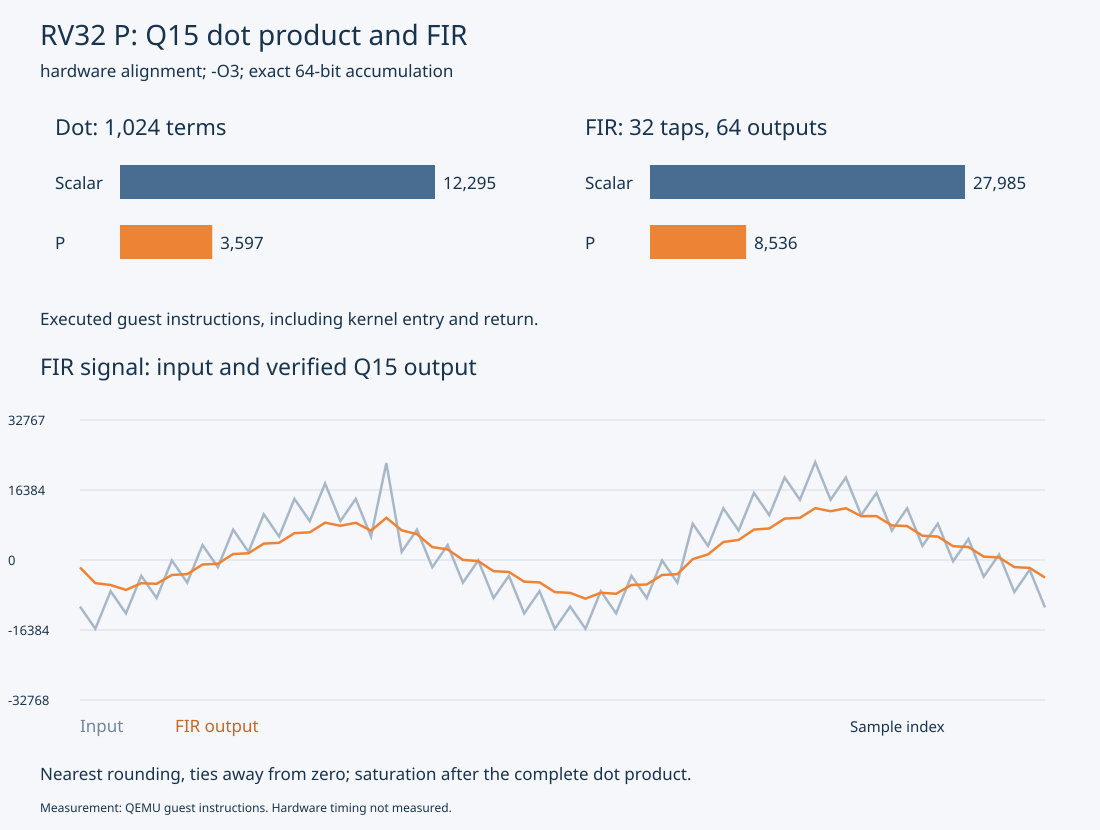

In [ ]:
_current_result()
figure = OUT / 'dsp.svg'
require(figure.is_file(), 'Missing visualization from the validated build')
try:
    from IPython.display import SVG, display
except ImportError:
    print('Open the verified visualization:', figure)
else:
    display(SVG(filename=str(figure)))


## Repeat

Change the selection, then rerun from the configuration cell. Default output directories separate target, policy and optimization. An explicit `RVP_DSP_OUT` is rebuilt in place.
